# Tree Models

*By Xingyao Chen.*

Decision trees, random forests, and gradient boosting predict continuous valence and the sad label (valence < 0.3).
The inputs are the 141 numeric features in train_features.csv; test_features.csv is used for final scoring.

## 1. Setup

Import the libraries and set the random seed and number of parallel CPU fits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier)
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score)

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3
N_JOBS = 2

Load the training features and targets. The text column track_genre is excluded because genre is already represented by the genre_* columns.

In [2]:
train_df = pd.read_csv("train_features.csv")

X = train_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y = train_df["valence"]
y_sad = train_df["sad"]

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 141)
Share of sad songs: 31.0%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,log_liveness,tempo,log_duration,mode,explicit,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,is_4_4,is_instrumental,is_slow,energy_sq,acousticness_sq,energy_x_acousticness,genre_acoustic,genre_afrobeat,genre_alt-rock,genre_alternative,genre_ambient,genre_anime,genre_black-metal,genre_bluegrass,genre_blues,genre_brazil,genre_breakbeat,genre_british,genre_cantopop,genre_chicago-house,genre_children,genre_chill,genre_classical,genre_club,genre_country,genre_dance,genre_dancehall,genre_death-metal,genre_deep-house,genre_detroit-techno,genre_disco,genre_disney,genre_drum-and-bass,genre_dub,genre_dubstep,genre_edm,genre_electro,genre_electronic,genre_emo,genre_folk,genre_forro,genre_french,genre_funk,genre_garage,genre_german,genre_gospel,genre_goth,genre_grindcore,genre_groove,genre_grunge,genre_guitar,genre_happy,genre_hard-rock,genre_hardcore,genre_hardstyle,genre_heavy-metal,genre_hip-hop,genre_honky-tonk,genre_house,genre_idm,genre_indian,genre_indie,genre_indie-pop,genre_industrial,genre_iranian,genre_j-dance,genre_j-idol,genre_j-pop,genre_j-rock,genre_jazz,genre_k-pop,genre_kids,genre_latin,genre_latino,genre_malay,genre_mandopop,genre_metal,genre_metalcore,genre_minimal-techno,genre_mpb,genre_new-age,genre_opera,genre_pagode,genre_party,genre_piano,genre_pop,genre_pop-film,genre_power-pop,genre_progressive-house,genre_psych-rock,genre_punk,genre_punk-rock,genre_r-n-b,genre_reggae,genre_reggaeton,genre_rock,genre_rock-n-roll,genre_rockabilly,genre_romance,genre_sad,genre_salsa,genre_samba,genre_sertanejo,genre_show-tunes,genre_singer-songwriter,genre_ska,genre_songwriter,genre_soul,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,0.345,0.351,-7.844,0.0343,0.7130,0.000000,-2.434974,96.538,11.926888,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.123201,0.508369,0.250263,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.469,0.650,-9.220,0.0344,0.0450,0.001110,-1.465338,123.929,12.995075,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0.422500,0.002025,0.029250,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0.622,0.459,-15.283,0.0449,0.0813,0.111000,-2.244316,135.033,12.737116,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.210681,0.006610,0.037317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0.320,0.384,-10.710,0.0362,0.2960,0.000006,-2.519498,119.353,12.634603,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0.147456,0.087616,0.113664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0.524,0.515,-7.478,0.0427,0.6740,0.000000,-2.263364,169.882,12.163410,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.265225,0.454276,0.347110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Cross-validation

Create five shuffled folds for regression and five stratified folds for classification. Stratification preserves the class proportions in each fold.

In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Evaluation functions

Calculate regression RMSE, MAE, and R2 using five-fold CV. Classification uses out-of-fold probabilities to calculate F1, ROC-AUC, and accuracy.

In [4]:
reg_results = []
clf_results = []

def eval_regressor(name, model, notes=""):
    scores = cross_validate(model, X, y, cv=kf, n_jobs=N_JOBS, error_score="raise",
                            scoring={"rmse": "neg_root_mean_squared_error",
                                     "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -scores["test_rmse"].mean(), "RMSE_std": scores["test_rmse"].std(),
           "MAE": -scores["test_mae"].mean(), "R2": scores["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), "
          f"MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def record_classifier(name, proba, threshold=0.5, notes=""):
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_sad, pred), "ROC_AUC": roc_auc_score(y_sad, proba),
           "accuracy": (pred == y_sad).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, "
          f"accuracy {row['accuracy']:.4f}")
    return row

def eval_classifier(name, model, notes=""):
    proba = cross_val_predict(model, X, y_sad, cv=skf,
                             method="predict_proba", n_jobs=N_JOBS)[:, 1]
    record_classifier(name, proba, notes=notes)
    return proba

### Tuning tables and plots

Display candidate scores and plot one parameter at a time, holding the other parameters at their selected values. Each plot is a separate figure.

In [5]:
def show_search(search):
    print("Best parameters:", search.best_params_)
    results = pd.DataFrame(search.cv_results_)
    parameters = [c for c in results if c.startswith("param_")]
    table = results[parameters + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    if "param_class_weight" in table:
        table["param_class_weight"] = table["param_class_weight"].fillna("None (equal weights)")
    if "param_max_depth" in table:
        table["param_max_depth"] = table["param_max_depth"].apply(lambda x: "No limit" if pd.isna(x) else int(x))
    if search.scoring == "neg_root_mean_squared_error":
        table[["mean_train_score", "mean_test_score"]] *= -1
    display(table.rename(columns={"mean_train_score": "training_score",
                                  "mean_test_score": "validation_score",
                                  "std_test_score": "validation_std",
                                  "rank_test_score": "rank"}).sort_values("rank"))

def plot_search(search, parameters, title):
    for parameter in parameters:
        results = pd.DataFrame(search.cv_results_)
        for other, value in search.best_params_.items():
            if other != parameter:
                results = results[[p[other] == value for p in results["params"]]]
        sign = -1 if search.scoring == "neg_root_mean_squared_error" else 1
        positions = np.arange(len(results))
        labels = [str(p[parameter]) for p in results["params"]]
        plt.figure(figsize=(8, 5))
        plt.plot(positions, sign * results["mean_train_score"], "o-", label="training")
        plt.errorbar(positions, sign * results["mean_test_score"],
                     yerr=results["std_test_score"], fmt="o-", capsize=3, label="validation")
        plt.xticks(positions, labels)
        plt.xlabel(parameter)
        plt.ylabel("RMSE" if sign == -1 else "ROC-AUC")
        plt.title(f"{title}: {parameter}")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 3. Initial models

Evaluate the mean-valence and always-not-sad baselines, then evaluate each tree model with its default parameters.

In [6]:
initial_reg = {
    "Decision tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
initial_clf = {
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"))
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"));

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000
Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


In [7]:
for name, model in initial_reg.items():
    eval_regressor(f"{name} (initial)", model)
pd.DataFrame(reg_results).round(4)

Decision tree (initial): RMSE 0.2574 (+/- 0.0018), MAE 0.1982, R2 0.0358
Random forest (initial): RMSE 0.1801 (+/- 0.0010), MAE 0.1433, R2 0.5278
Gradient boosting (initial): RMSE 0.1870 (+/- 0.0015), MAE 0.1521, R2 0.4910


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,Decision tree (initial),0.2574,0.0018,0.1982,0.0358,
2,Random forest (initial),0.1801,0.0010,0.1433,0.5278,
3,Gradient boosting (initial),0.1870,0.0015,0.1521,0.4910,


In [8]:
for name, model in initial_clf.items():
    eval_classifier(f"{name} (initial)", model)
pd.DataFrame(clf_results).round(4)

Decision tree (initial): F1 0.5732, ROC-AUC 0.6908, accuracy 0.7355
Random forest (initial): F1 0.6500, ROC-AUC 0.8663, accuracy 0.8090
Gradient boosting (initial): F1 0.6207, ROC-AUC 0.8565, accuracy 0.7998


,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.5,0.0000,0.5000,0.6902,
1,Decision tree (initial),0.5,0.5732,0.6908,0.7355,
2,Random forest (initial),0.5,0.6500,0.8663,0.8090,
3,Gradient boosting (initial),0.5,0.6207,0.8565,0.7998,


## 4. Regression tuning

Select parameters by the lowest mean CV RMSE.

### 4.1 Decision tree

Compare maximum depth and minimum samples per leaf.

Best parameters: {'max_depth': 12, 'min_samples_leaf': 50}


,param_max_depth,param_min_samples_leaf,training_score,validation_score,validation_std,rank
11,12,50,1.870344e-01,0.200491,0.001191,1
14,16,50,1.836703e-01,0.200805,0.001212,2
20,No limit,50,1.834093e-01,0.200827,0.001160,3
17,24,50,1.834093e-01,0.200827,0.001160,3
10,12,10,1.772562e-01,0.203061,0.001347,5
8,8,50,1.982739e-01,0.203997,0.000989,6
7,8,10,1.972116e-01,0.204201,0.000936,7
6,8,1,1.968662e-01,0.204564,0.000986,8
9,12,1,1.723652e-01,0.207024,0.001127,9
13,16,10,1.593373e-01,0.209422,0.001582,10


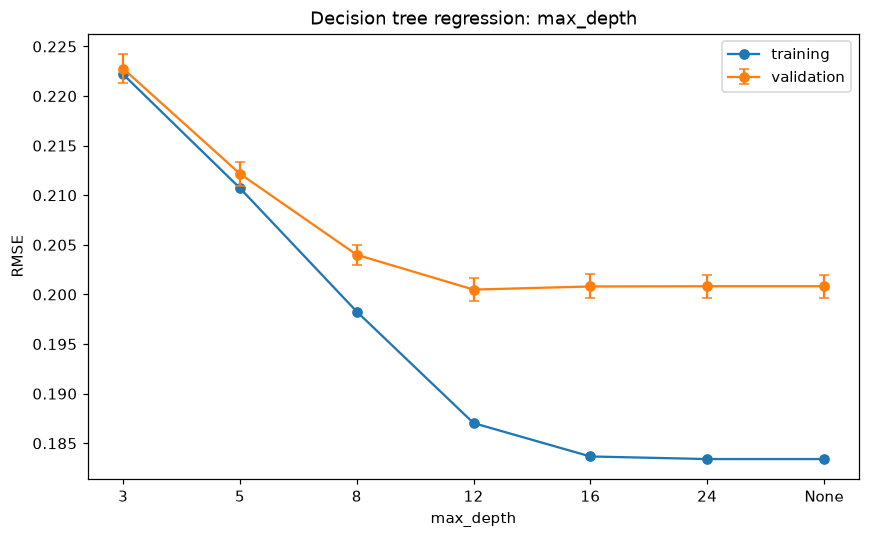

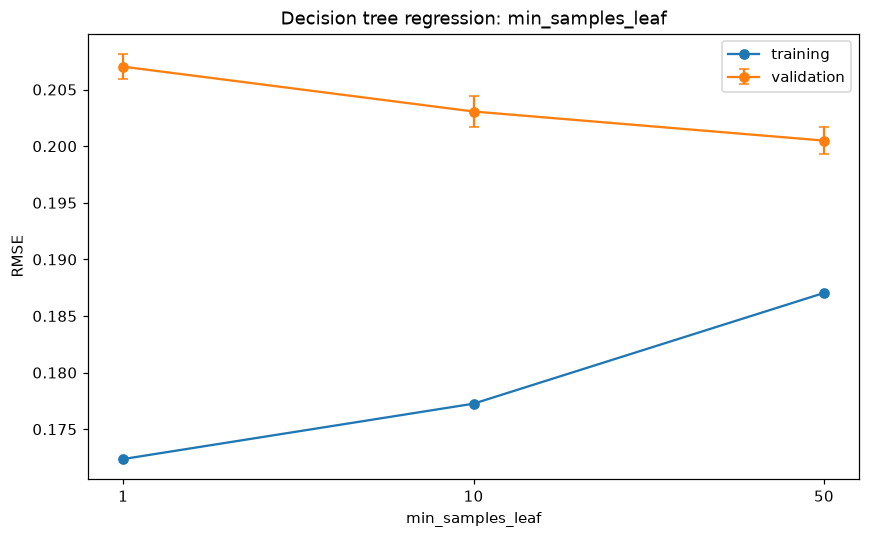

In [9]:
tree_params = {
    "max_depth": [3, 5, 8, 12, 16, 24, None],
    "min_samples_leaf": [1, 10, 50],
}
tree_reg_grid = GridSearchCV(initial_reg["Decision tree"], tree_params,
                             cv=kf, scoring="neg_root_mean_squared_error",
                             return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
tree_reg_grid.fit(X, y)
show_search(tree_reg_grid)
plot_search(tree_reg_grid, list(tree_params), "Decision tree regression")

### 4.2 Random forest

First tune tree depth, leaf size, and feature sampling with 100 trees. Then compare the number of trees using the selected structure.

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,param_max_depth,param_max_features,param_min_samples_leaf,training_score,validation_score,validation_std,rank
12,No limit,sqrt,1,0.067169,0.178755,0.000985,1
15,No limit,1.0,1,0.067433,0.180141,0.000992,2
9,16,1.0,1,0.125874,0.181878,0.001089,3
16,No limit,1.0,5,0.114839,0.181989,0.001191,4
10,16,1.0,5,0.137767,0.182887,0.001153,5
13,No limit,sqrt,5,0.157279,0.184149,0.001152,6
17,No limit,1.0,20,0.161898,0.185717,0.001228,7
11,16,1.0,20,0.163932,0.185942,0.001244,8
6,16,sqrt,1,0.174423,0.192032,0.001211,9
14,No limit,sqrt,20,0.184151,0.192188,0.001297,10


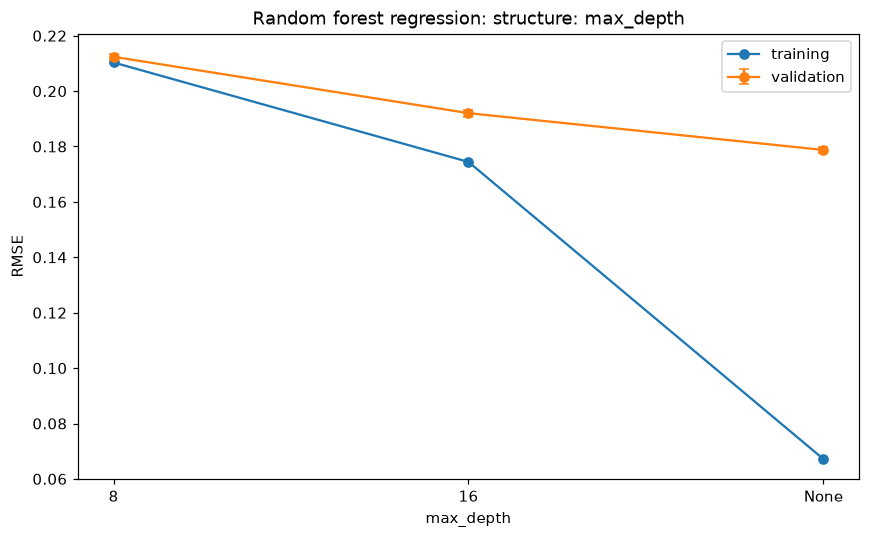

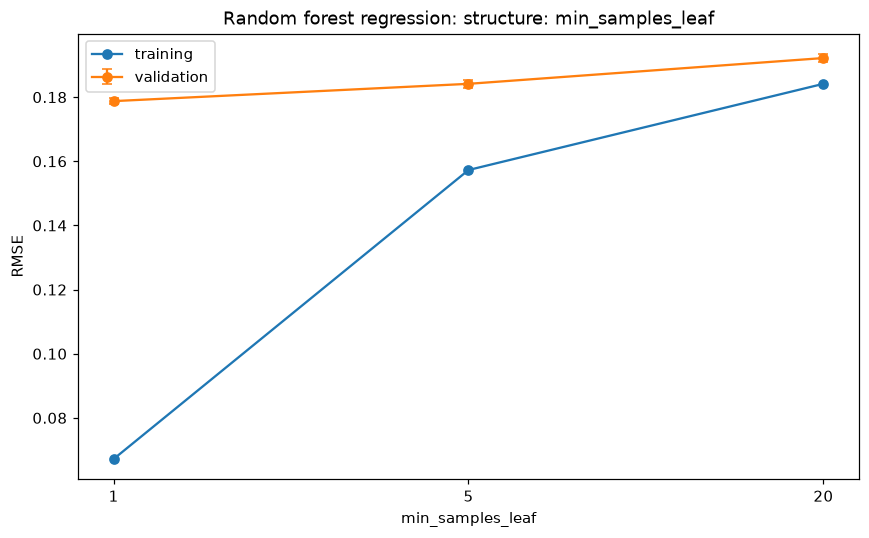

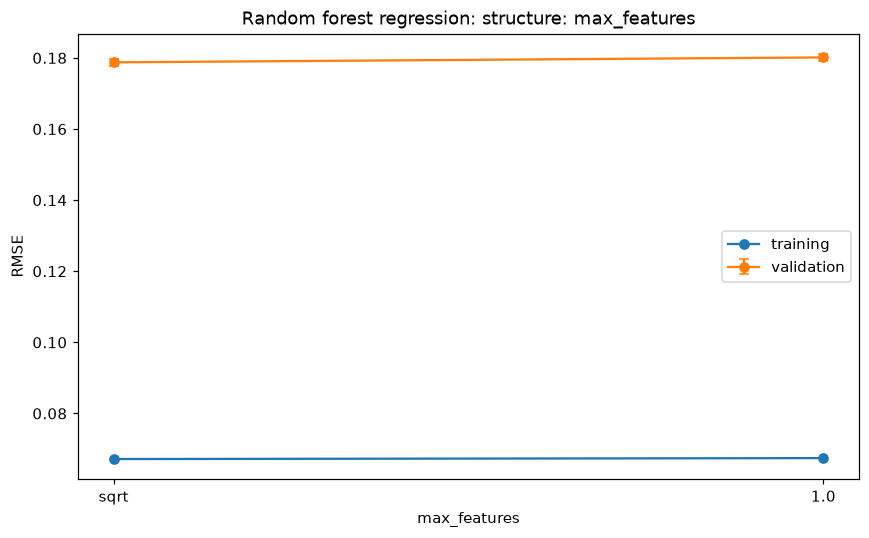

In [10]:
forest_params = {
    "max_depth": [8, 16, None],
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 1.0],
}
forest_reg_structure = GridSearchCV(initial_reg["Random forest"], forest_params,
                                    cv=kf, scoring="neg_root_mean_squared_error",
                                    return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
forest_reg_structure.fit(X, y)
show_search(forest_reg_structure)
plot_search(forest_reg_structure, list(forest_params), "Random forest regression: structure")

Best parameters: {'n_estimators': 400}


,param_n_estimators,training_score,validation_score,validation_std,rank
3,400,0.065830,0.177995,0.000935,1
2,200,0.066272,0.178104,0.000865,2
1,100,0.067169,0.178755,0.000985,3
0,50,0.068807,0.179913,0.000990,4


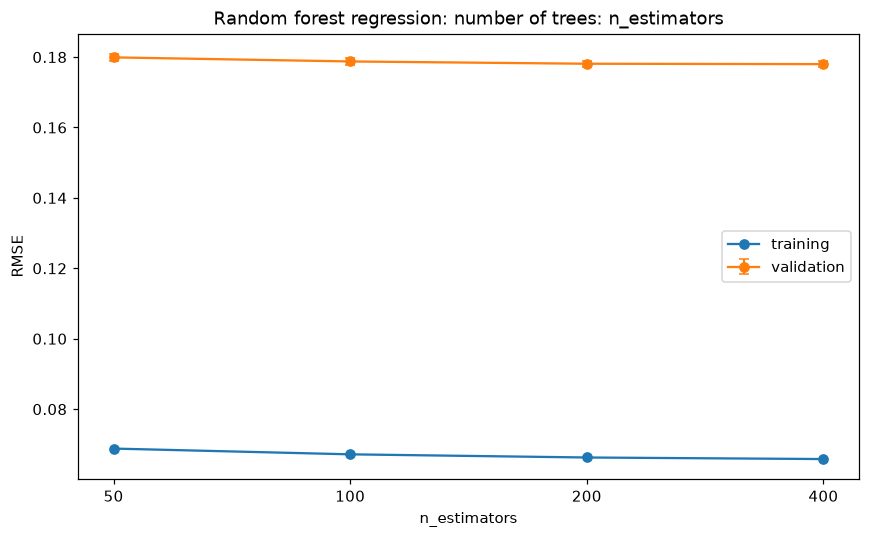

In [11]:
forest_size_params = {"n_estimators": [50, 100, 200, 400]}
forest_reg_grid = GridSearchCV(clone(forest_reg_structure.best_estimator_), forest_size_params,
                               cv=kf, scoring="neg_root_mean_squared_error",
                               return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
forest_reg_grid.fit(X, y)
show_search(forest_reg_grid)
plot_search(forest_reg_grid, list(forest_size_params), "Random forest regression: number of trees")

### 4.3 Gradient boosting

Compare learning rate, tree depth, and the number of boosting stages. Plot training and validation scores separately.

Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}


,param_learning_rate,param_max_depth,param_n_estimators,training_score,validation_score,validation_std,rank
17,0.10,5,400,0.150254,0.169473,0.001039,1
23,0.30,3,400,0.156465,0.170142,0.000809,2
25,0.30,5,150,0.148570,0.171477,0.001038,3
26,0.30,5,400,0.125368,0.172356,0.001061,4
20,0.30,2,400,0.167413,0.172771,0.000948,5
22,0.30,3,150,0.167434,0.173528,0.000784,6
14,0.10,3,400,0.168592,0.173969,0.001159,7
16,0.10,5,150,0.165410,0.174654,0.000882,8
24,0.30,5,50,0.166126,0.176070,0.001303,9
8,0.03,5,400,0.168971,0.176493,0.001044,10


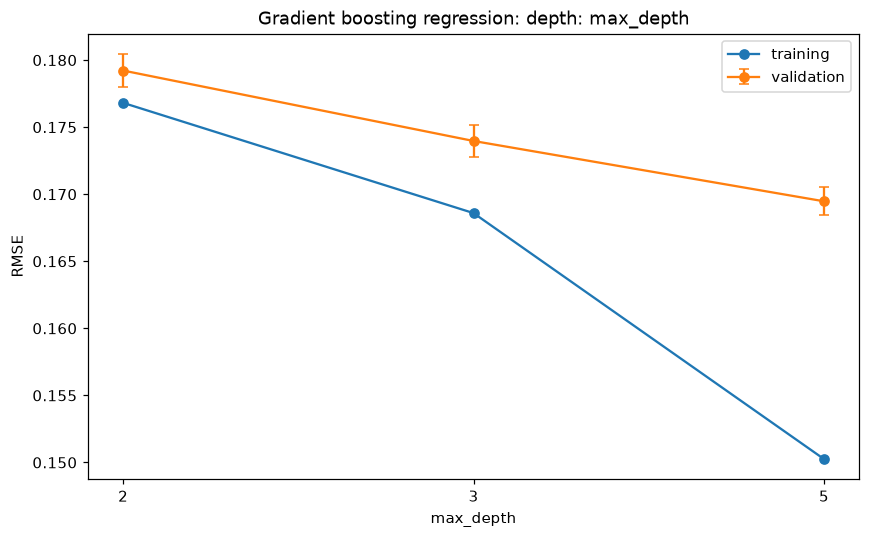

In [12]:
boost_params = {
    "learning_rate": [0.03, 0.1, 0.3],
    "max_depth": [2, 3, 5],
    "n_estimators": [50, 150, 400],
}
boost_reg_grid = GridSearchCV(initial_reg["Gradient boosting"], boost_params,
                              cv=kf, scoring="neg_root_mean_squared_error",
                              return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=2)
boost_reg_grid.fit(X, y)
show_search(boost_reg_grid)
plot_search(boost_reg_grid, ["max_depth"], "Gradient boosting regression: depth")

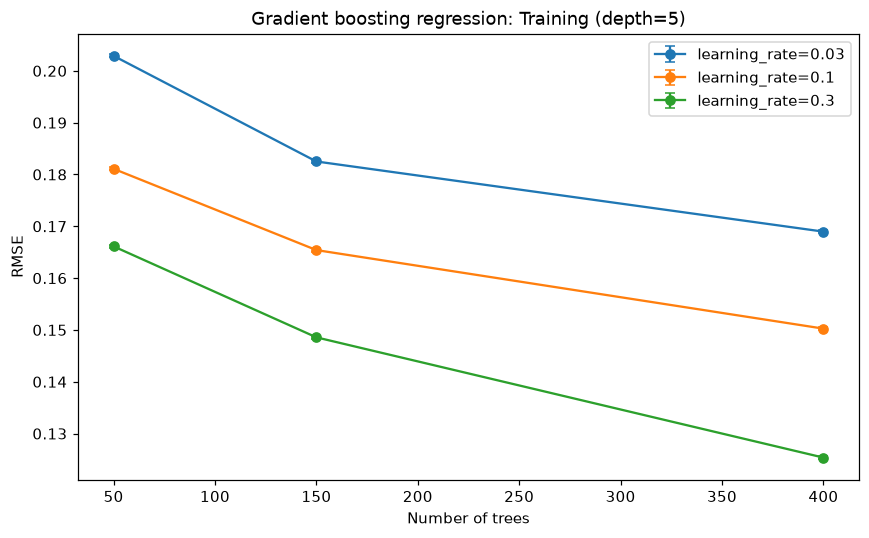

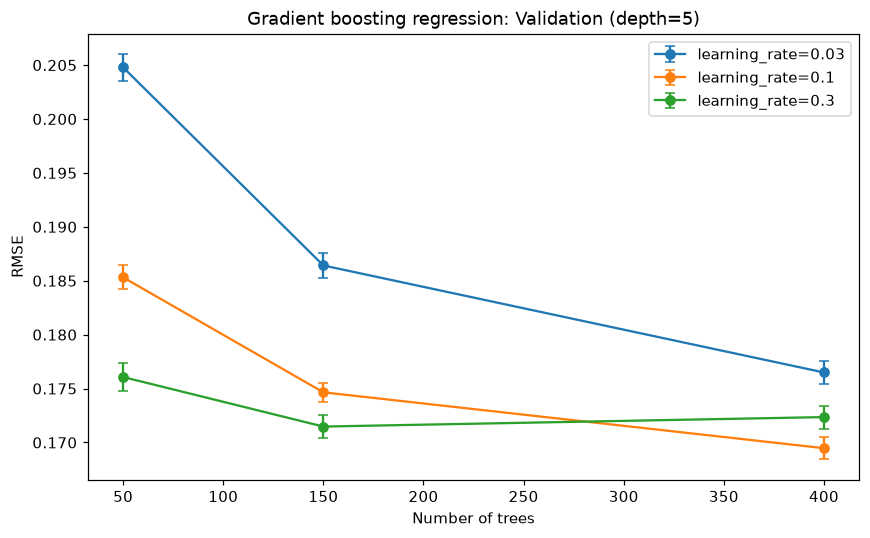

In [13]:
def plot_boosting(search, title):
    results = pd.DataFrame(search.cv_results_)
    depth = search.best_params_["max_depth"]
    sign = -1 if search.scoring == "neg_root_mean_squared_error" else 1
    for split, label in [("train", "Training"), ("test", "Validation")]:
        plt.figure(figsize=(8, 5))
        for rate in search.param_grid["learning_rate"]:
            rows = results[[p["max_depth"] == depth and p["learning_rate"] == rate
                            for p in results["params"]]].sort_values("param_n_estimators")
            plt.errorbar(rows["param_n_estimators"].astype(int), sign * rows[f"mean_{split}_score"],
                         yerr=rows[f"std_{split}_score"], fmt="o-", capsize=3,
                         label=f"learning_rate={rate}")
        plt.xlabel("Number of trees")
        plt.ylabel("RMSE" if sign == -1 else "ROC-AUC")
        plt.title(f"{title}: {label} (depth={depth})")
        plt.legend()
        plt.tight_layout()
        plt.show()

plot_boosting(boost_reg_grid, "Gradient boosting regression")

### 4.4 Tuned regression scores

Calculate RMSE, MAE, and R2 for each selected regressor and record its parameters.

In [14]:
tuned_reg = {
    "Decision tree (tuned)": tree_reg_grid.best_estimator_,
    "Random forest (tuned)": forest_reg_grid.best_estimator_,
    "Gradient boosting (tuned)": boost_reg_grid.best_estimator_,
}
reg_notes = {
    "Decision tree (tuned)": str(tree_reg_grid.best_params_),
    "Random forest (tuned)": str({**forest_reg_structure.best_params_, **forest_reg_grid.best_params_}),
    "Gradient boosting (tuned)": str(boost_reg_grid.best_params_),
}
for name, model in tuned_reg.items():
    eval_regressor(name, model, notes=reg_notes[name])
pd.DataFrame(reg_results).round(4)

Decision tree (tuned): RMSE 0.2005 (+/- 0.0012), MAE 0.1597, R2 0.4150
Random forest (tuned): RMSE 0.1780 (+/- 0.0009), MAE 0.1440, R2 0.5389
Gradient boosting (tuned): RMSE 0.1695 (+/- 0.0010), MAE 0.1341, R2 0.5820


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,Decision tree (initial),0.2574,0.0018,0.1982,0.0358,
2,Random forest (initial),0.1801,0.0010,0.1433,0.5278,
3,Gradient boosting (initial),0.1870,0.0015,0.1521,0.4910,
4,Decision tree (tuned),0.2005,0.0012,0.1597,0.4150,"{'max_depth': 12, 'min_samples_l..."
5,Random forest (tuned),0.1780,0.0009,0.1440,0.5389,"{'max_depth': None, 'max_feature..."
6,Gradient boosting (tuned),0.1695,0.0010,0.1341,0.5820,"{'learning_rate': 0.1, 'max_dept..."


## 5. Classification tuning

Select classifier parameters by the highest mean CV ROC-AUC.

### 5.1 Decision tree

Compare depth, leaf size, and class weighting; None gives equal class weights, while balanced increases the weight of the less frequent class.

Best parameters: {'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 50}


,param_class_weight,param_max_depth,param_min_samples_leaf,training_score,validation_score,validation_std,rank
11,None (equal weights),12,50,0.863923,0.819276,0.003999,1
32,balanced,12,50,0.866459,0.818323,0.003056,2
14,None (equal weights),16,50,0.872527,0.817745,0.003055,3
20,None (equal weights),No limit,50,0.873459,0.817546,0.003333,4
17,None (equal weights),24,50,0.873459,0.817546,0.003333,4
29,balanced,8,50,0.838518,0.817388,0.002696,6
28,balanced,8,10,0.841515,0.817006,0.003861,7
35,balanced,16,50,0.873761,0.816325,0.003899,8
41,balanced,No limit,50,0.874955,0.816290,0.003801,9
38,balanced,24,50,0.874955,0.816290,0.003801,9


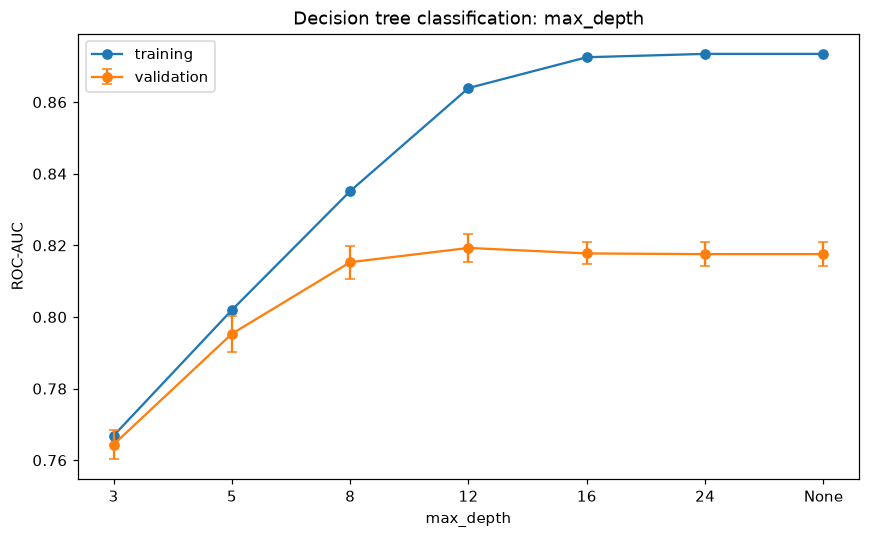

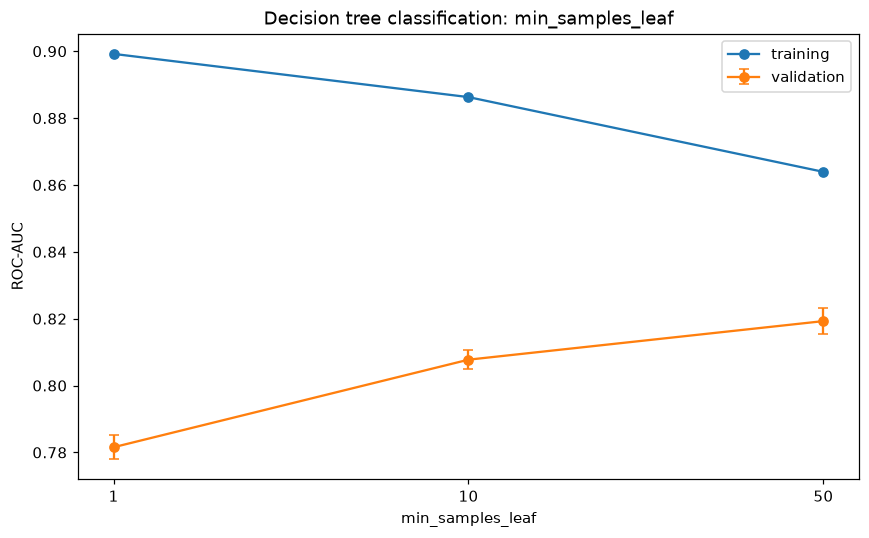

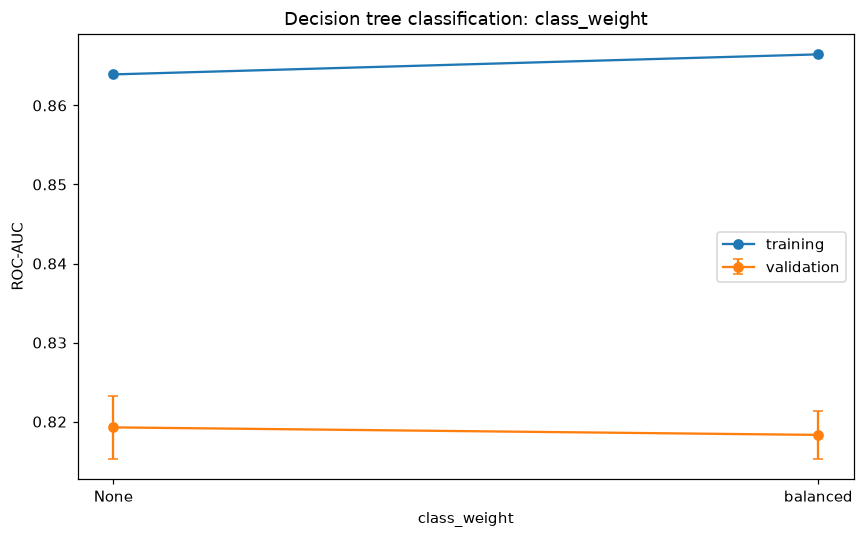

In [15]:
tree_clf_params = {**tree_params, "class_weight": [None, "balanced"]}
tree_clf_grid = GridSearchCV(initial_clf["Decision tree"], tree_clf_params,
                             cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                             n_jobs=N_JOBS, verbose=1)
tree_clf_grid.fit(X, y_sad)
show_search(tree_clf_grid)
plot_search(tree_clf_grid, list(tree_clf_params), "Decision tree classification")

### 5.2 Random forest

Tune forest structure with 100 trees, then compare tree count and class weighting.

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,param_max_depth,param_max_features,param_min_samples_leaf,training_score,validation_score,validation_std,rank
12,No limit,sqrt,1,1.000000,0.866338,0.002921,1
15,No limit,1.0,1,1.000000,0.863370,0.003266,2
13,No limit,sqrt,5,0.949261,0.862711,0.003326,3
9,16,1.0,1,0.981181,0.861296,0.003085,4
16,No limit,1.0,5,0.989009,0.860113,0.002831,5
10,16,1.0,5,0.964877,0.859164,0.002720,6
17,No limit,1.0,20,0.926300,0.855092,0.003176,7
11,16,1.0,20,0.920061,0.854590,0.003206,8
6,16,sqrt,1,0.921489,0.852953,0.003810,9
14,No limit,sqrt,20,0.884808,0.851886,0.004256,10


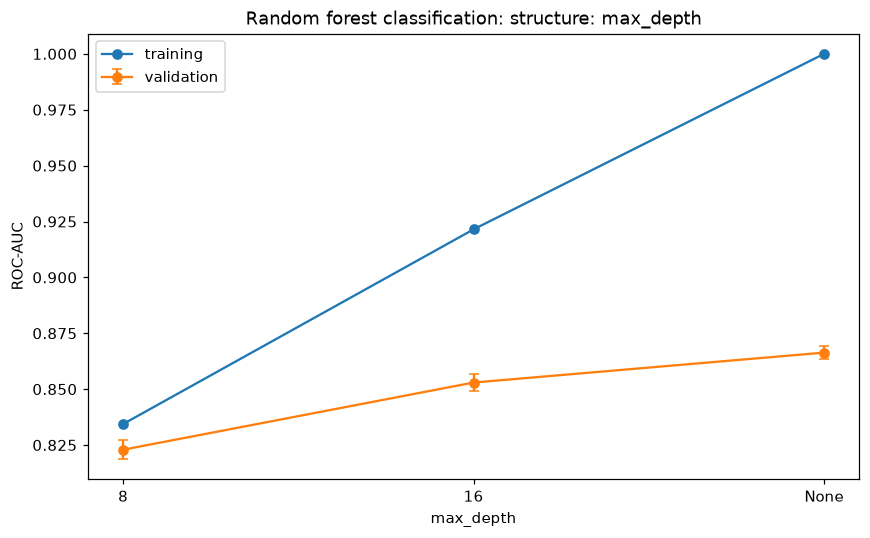

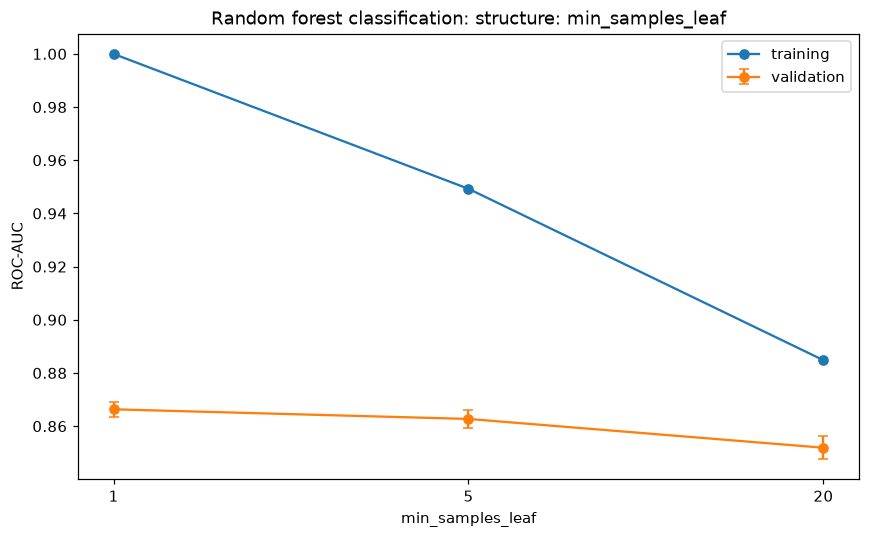

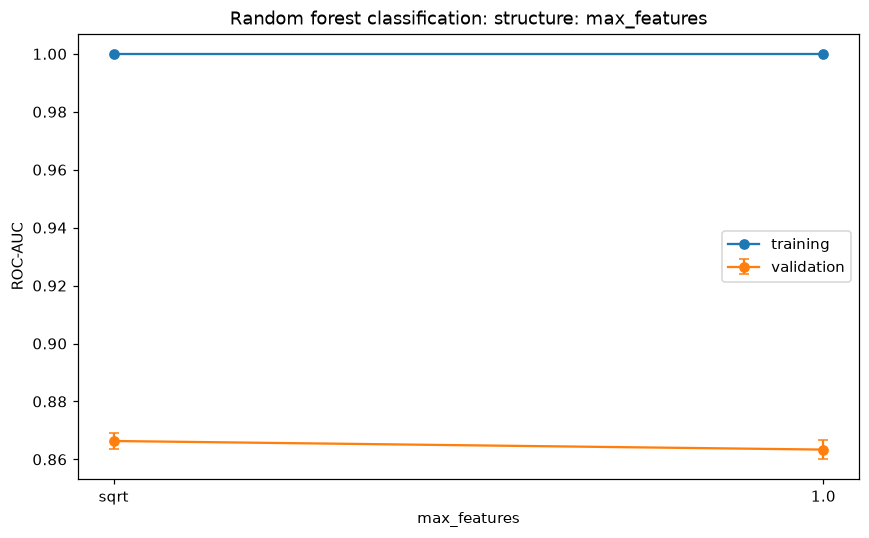

In [16]:
forest_clf_structure = GridSearchCV(initial_clf["Random forest"], forest_params,
                                    cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                                    n_jobs=N_JOBS, verbose=1)
forest_clf_structure.fit(X, y_sad)
show_search(forest_clf_structure)
plot_search(forest_clf_structure, list(forest_params), "Random forest classification: structure")

Best parameters: {'class_weight': 'balanced', 'n_estimators': 400}


,param_class_weight,param_n_estimators,training_score,validation_score,validation_std,rank
7,balanced,400,1.0,0.870670,0.003510,1
6,balanced,200,1.0,0.870022,0.003762,2
3,None (equal weights),400,1.0,0.869976,0.003011,3
2,None (equal weights),200,1.0,0.868668,0.002983,4
5,balanced,100,1.0,0.867976,0.003695,5
1,None (equal weights),100,1.0,0.866338,0.002921,6
4,balanced,50,1.0,0.864083,0.003579,7
0,None (equal weights),50,1.0,0.861215,0.002744,8


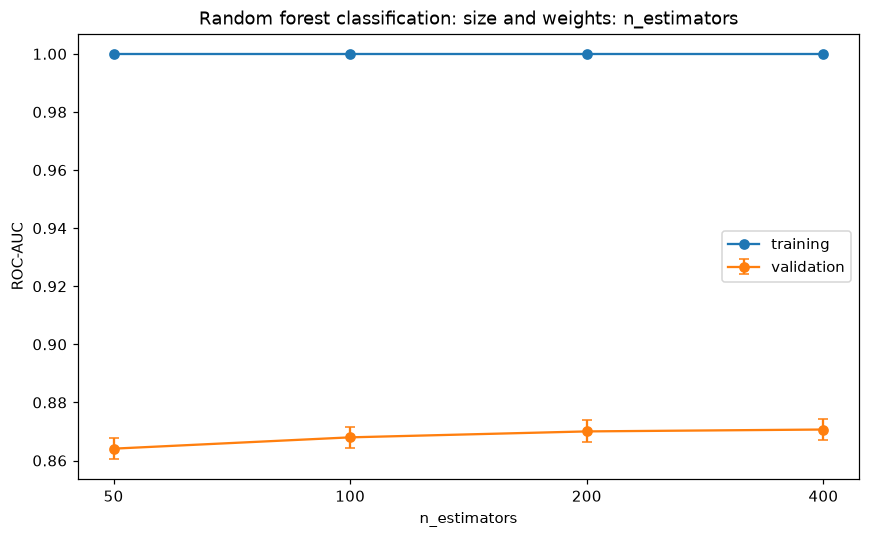

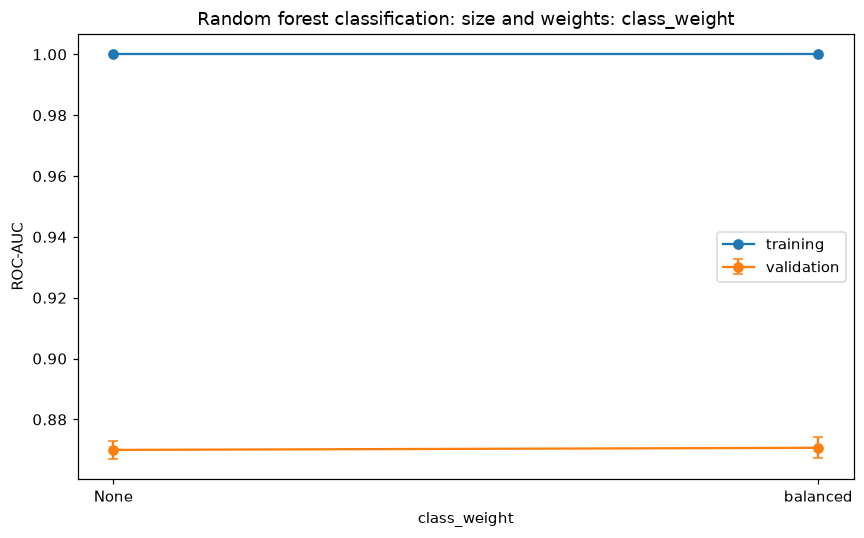

In [17]:
forest_clf_params = {**forest_size_params, "class_weight": [None, "balanced"]}
forest_clf_grid = GridSearchCV(clone(forest_clf_structure.best_estimator_), forest_clf_params,
                               cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                               n_jobs=N_JOBS, verbose=1)
forest_clf_grid.fit(X, y_sad)
show_search(forest_clf_grid)
plot_search(forest_clf_grid, list(forest_clf_params), "Random forest classification: size and weights")

### 5.3 Gradient boosting

Compare learning rate, depth, and tree count using CV ROC-AUC.

Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}


,param_learning_rate,param_max_depth,param_n_estimators,training_score,validation_score,validation_std,rank
17,0.10,5,400,0.933774,0.880805,0.002449,1
23,0.30,3,400,0.921295,0.879428,0.002287,2
20,0.30,2,400,0.895391,0.879387,0.002795,3
14,0.10,3,400,0.895024,0.877459,0.002926,4
22,0.30,3,150,0.897344,0.877084,0.003210,5
25,0.30,5,150,0.937211,0.876025,0.002719,6
16,0.10,5,150,0.903876,0.875048,0.002751,7
8,0.03,5,400,0.897447,0.872592,0.003261,8
24,0.30,5,50,0.902335,0.872104,0.003383,9
26,0.30,5,400,0.977867,0.871517,0.002956,10


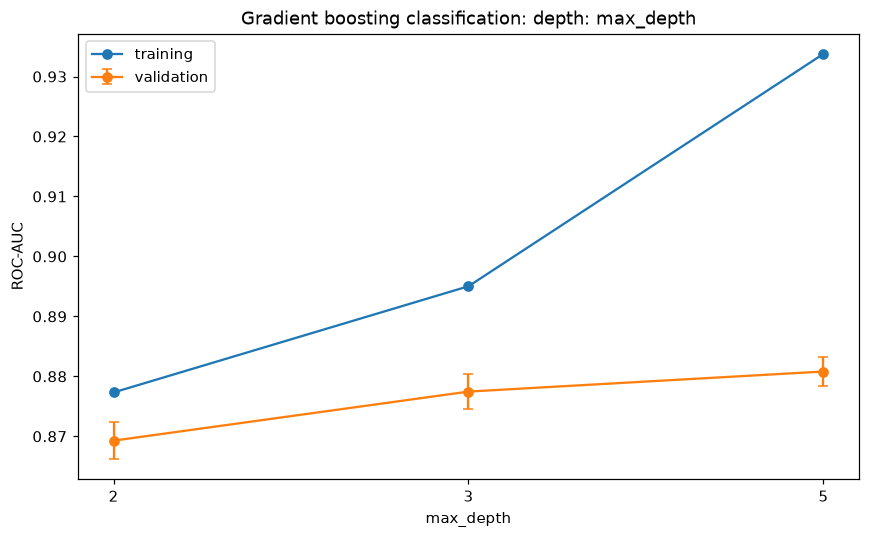

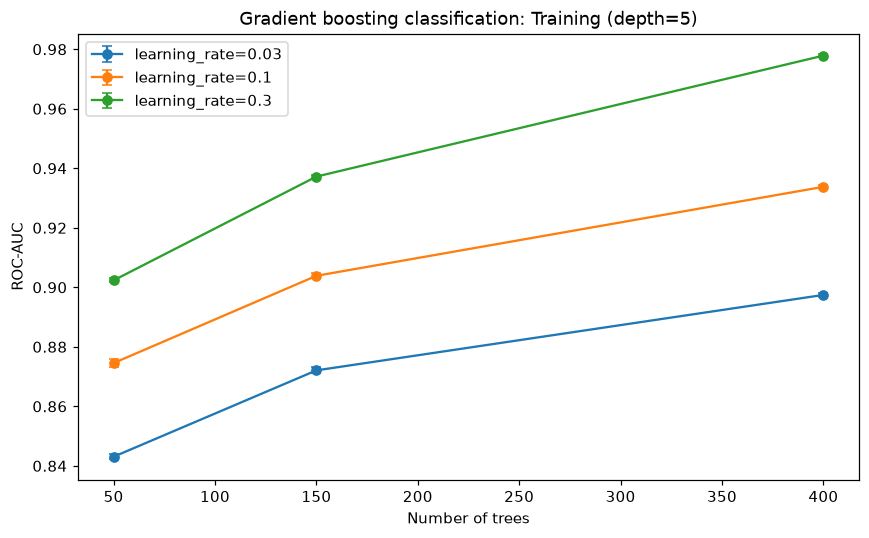

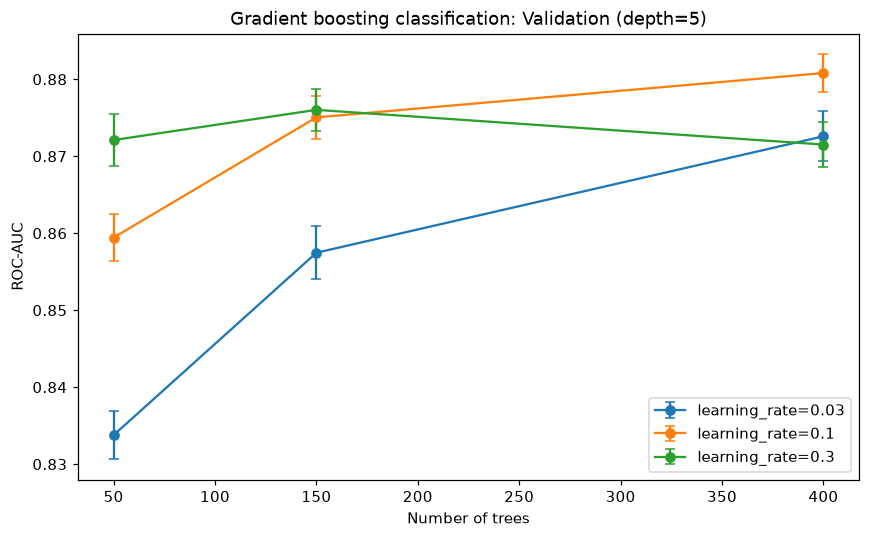

In [18]:
boost_clf_grid = GridSearchCV(initial_clf["Gradient boosting"], boost_params,
                              cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                              n_jobs=N_JOBS, verbose=2)
boost_clf_grid.fit(X, y_sad)
show_search(boost_clf_grid)
plot_search(boost_clf_grid, ["max_depth"], "Gradient boosting classification: depth")
plot_boosting(boost_clf_grid, "Gradient boosting classification")

### 5.4 Decision thresholds

For each classifier, generate out-of-fold probabilities and test thresholds from 0.05 to 0.95 in steps of 0.01. Select the threshold with the highest OOF F1 and also report F1 at 0.5.

Decision tree (tuned, threshold 0.33): F1 0.6382, ROC-AUC 0.8193, accuracy 0.7481
Decision tree (tuned, threshold 0.50): F1 0.5972, ROC-AUC 0.8193, accuracy 0.7763
Random forest (tuned, threshold 0.45): F1 0.6980, ROC-AUC 0.8706, accuracy 0.7957
Random forest (tuned, threshold 0.50): F1 0.6919, ROC-AUC 0.8706, accuracy 0.8064
Gradient boosting (tuned, threshold 0.36): F1 0.7092, ROC-AUC 0.8808, accuracy 0.8093
Gradient boosting (tuned, threshold 0.50): F1 0.6819, ROC-AUC 0.8808, accuracy 0.8184


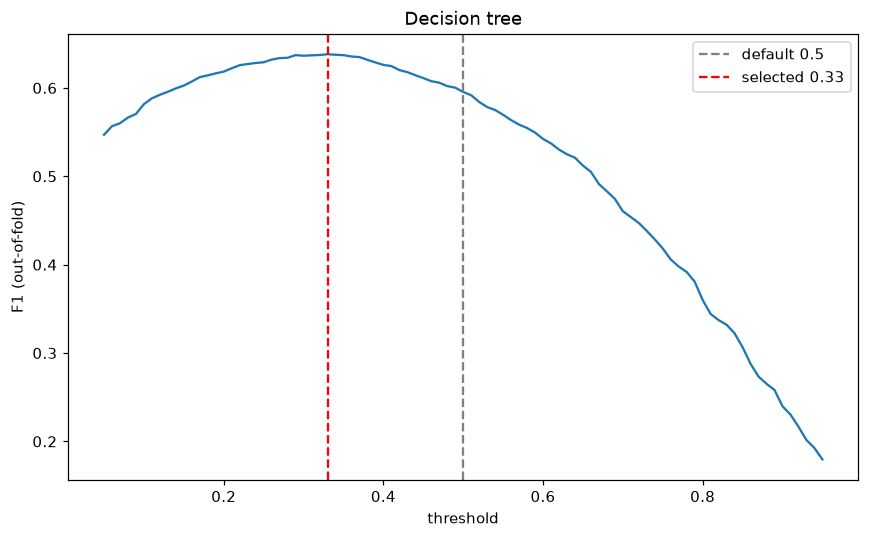

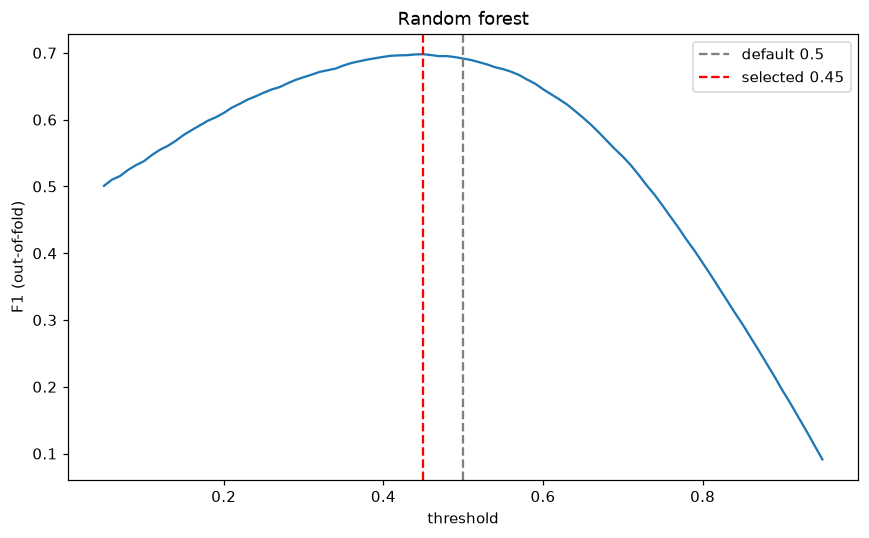

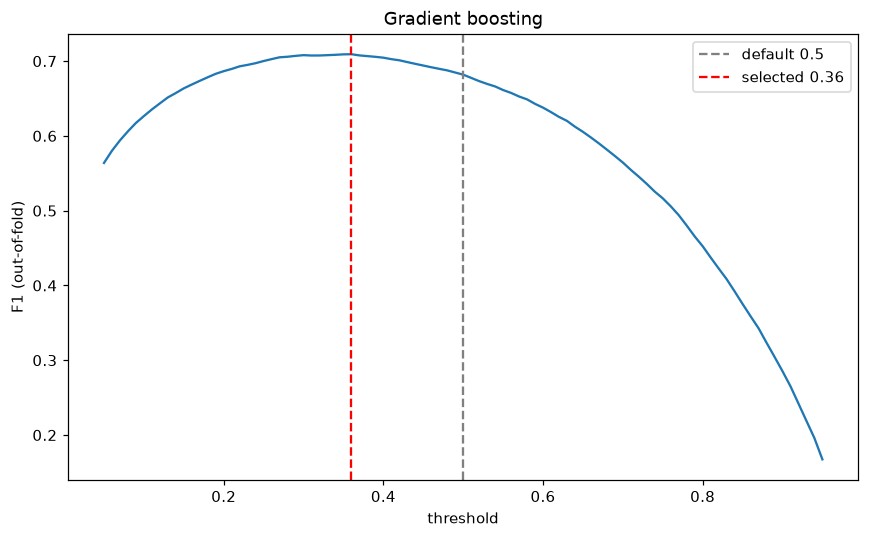

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,Decision tree (initial),0.50,0.5732,0.6908,0.7355,
2,Random forest (initial),0.50,0.6500,0.8663,0.8090,
3,Gradient boosting (initial),0.50,0.6207,0.8565,0.7998,
4,"Decision tree (tuned, threshold 0.33)",0.33,0.6382,0.8193,0.7481,"{'class_weight': None, 'max_depth': 12, 'min_s..."
5,"Decision tree (tuned, threshold 0.50)",0.50,0.5972,0.8193,0.7763,"{'class_weight': None, 'max_depth': 12, 'min_s..."
6,"Random forest (tuned, threshold 0.45)",0.45,0.6980,0.8706,0.7957,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
7,"Random forest (tuned, threshold 0.50)",0.50,0.6919,0.8706,0.8064,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
8,"Gradient boosting (tuned, threshold 0.36)",0.36,0.7092,0.8808,0.8093,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
9,"Gradient boosting (tuned, threshold 0.50)",0.50,0.6819,0.8808,0.8184,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."


In [19]:
tuned_clf = {
    "Decision tree": tree_clf_grid.best_estimator_,
    "Random forest": forest_clf_grid.best_estimator_,
    "Gradient boosting": boost_clf_grid.best_estimator_,
}
clf_notes = {
    "Decision tree": str(tree_clf_grid.best_params_),
    "Random forest": str({**forest_clf_structure.best_params_, **forest_clf_grid.best_params_}),
    "Gradient boosting": str(boost_clf_grid.best_params_),
}
thresholds = np.arange(0.05, 0.96, 0.01)
best_thresholds = {}
clf_oof = {}

for name, model in tuned_clf.items():
    proba = cross_val_predict(model, X, y_sad, cv=skf, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    clf_oof[name] = proba
    f1s = [f1_score(y_sad, (proba >= t).astype(int)) for t in thresholds]
    best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)
    best_thresholds[name] = best_t
    for t in sorted({0.5, best_t}):
        record_classifier(f"{name} (tuned, threshold {t:.2f})", proba,
                          threshold=t, notes=clf_notes[name])
    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, f1s)
    plt.axvline(0.5, color="gray", ls="--", label="default 0.5")
    plt.axvline(best_t, color="red", ls="--", label=f"selected {best_t:.2f}")
    plt.title(name)
    plt.xlabel("threshold")
    plt.ylabel("F1 (out-of-fold)")
    plt.legend()
    plt.tight_layout()
    plt.show()
pd.DataFrame(clf_results).round(4)

### 5.5 Classification diagnostics

Select the classifier with the highest OOF ROC-AUC and plot its confusion matrix, ROC curve, and precision-recall curve separately.

Selected classifier: Gradient boosting | threshold: 0.36


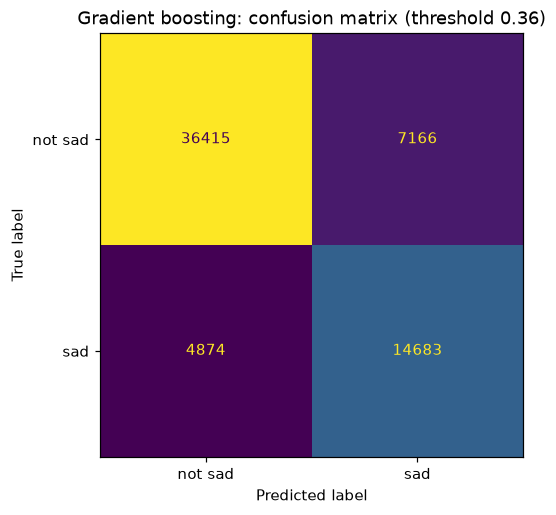

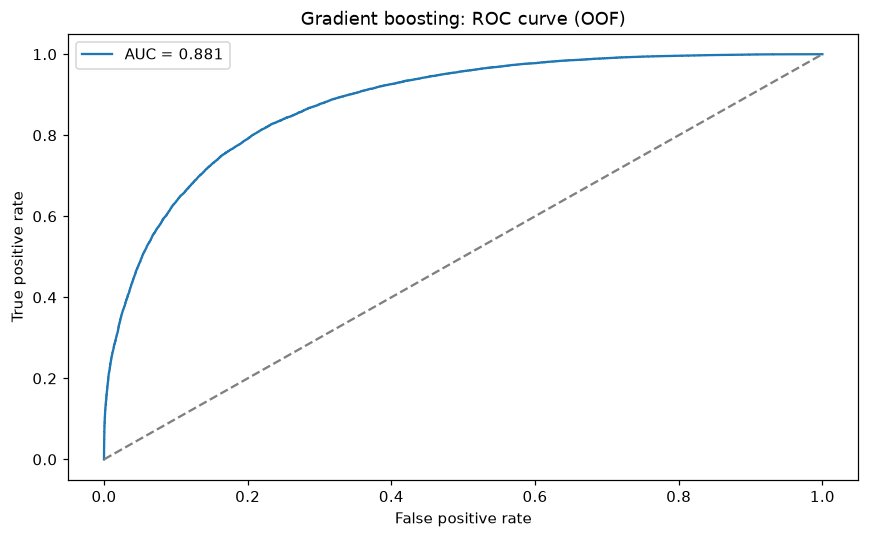

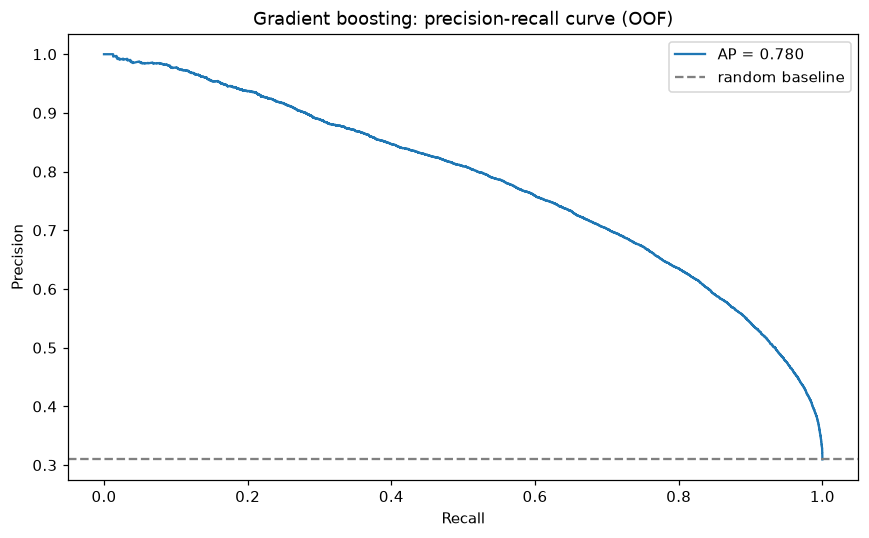

In [20]:
best_clf_name = max(clf_oof, key=lambda name: roc_auc_score(y_sad, clf_oof[name]))
oof_proba = clf_oof[best_clf_name]
best_t = best_thresholds[best_clf_name]
print("Selected classifier:", best_clf_name, "| threshold:", best_t)

ConfusionMatrixDisplay.from_predictions(y_sad, (oof_proba >= best_t).astype(int),
                                        display_labels=["not sad", "sad"], colorbar=False)
plt.title(f"{best_clf_name}: confusion matrix (threshold {best_t:.2f})")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_sad, oof_proba):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"{best_clf_name}: ROC curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AP = {average_precision_score(y_sad, oof_proba):.3f}")
plt.axhline(y_sad.mean(), color="gray", ls="--", label="random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"{best_clf_name}: precision-recall curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Model interpretation

### 6.1 Decision tree rules

Display the top levels of the selected regression tree using the feature values in the input data.

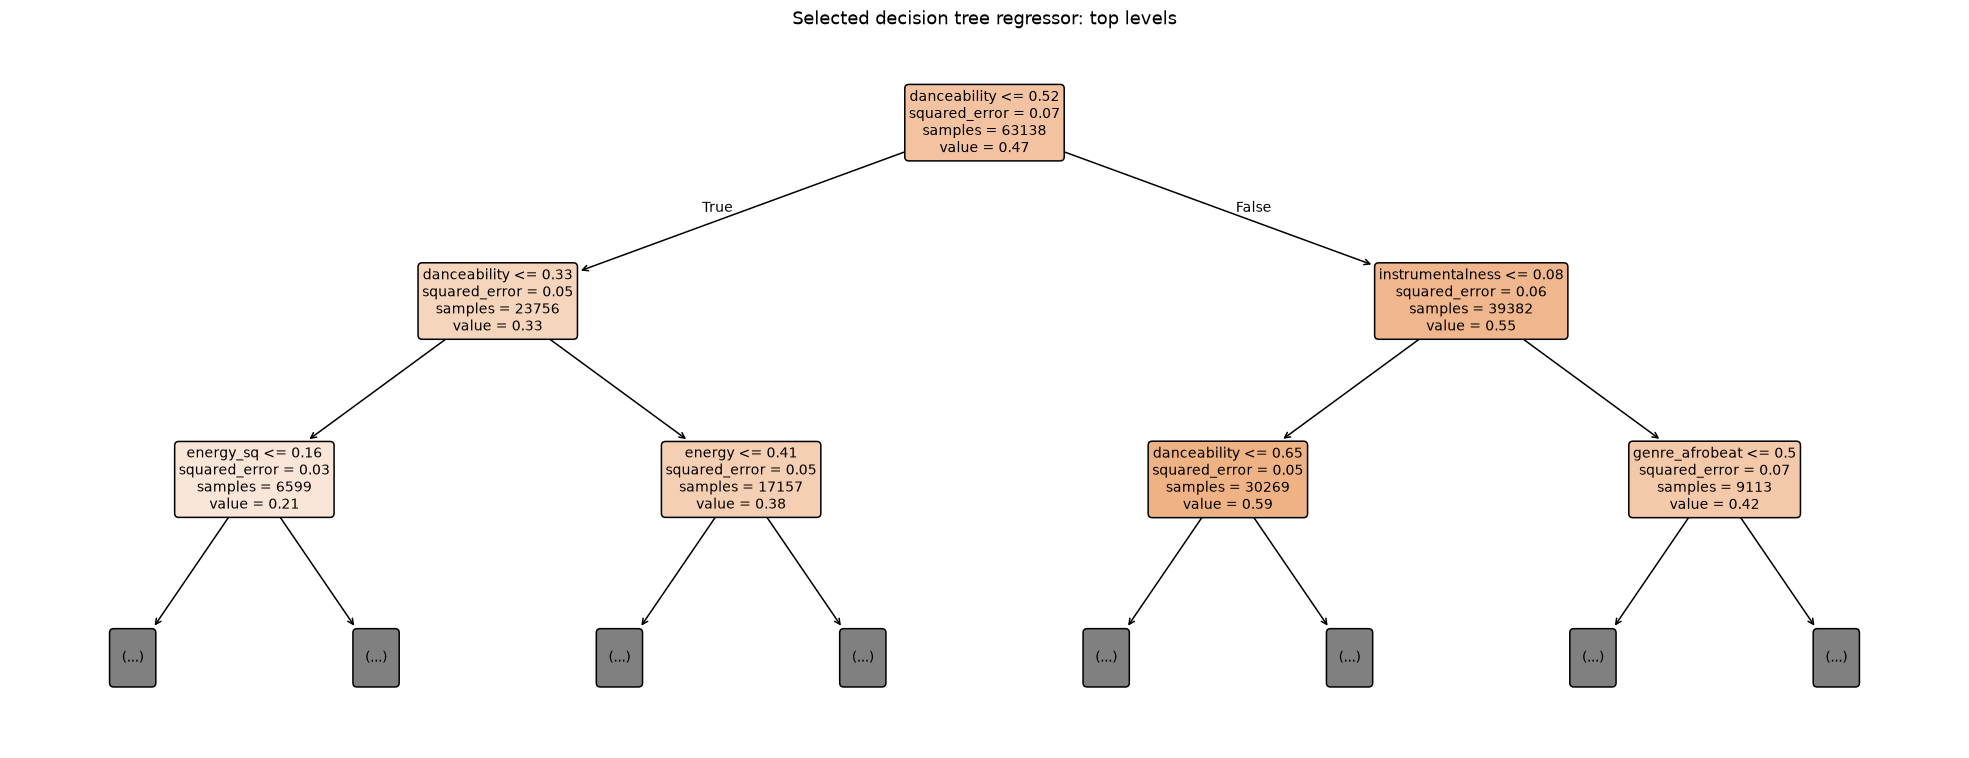

In [21]:
tree_for_plot = tree_reg_grid.best_estimator_
feature_names = X.columns
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree_for_plot, feature_names=feature_names,
          max_depth=2, filled=True, rounded=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Selected decision tree regressor: top levels")
plt.tight_layout()
plt.show()

### 6.2 Feature importance

For the selected regressor and classifier, plot the 15 largest built-in feature importances. These describe the fitted trees' splits, not causal effects.

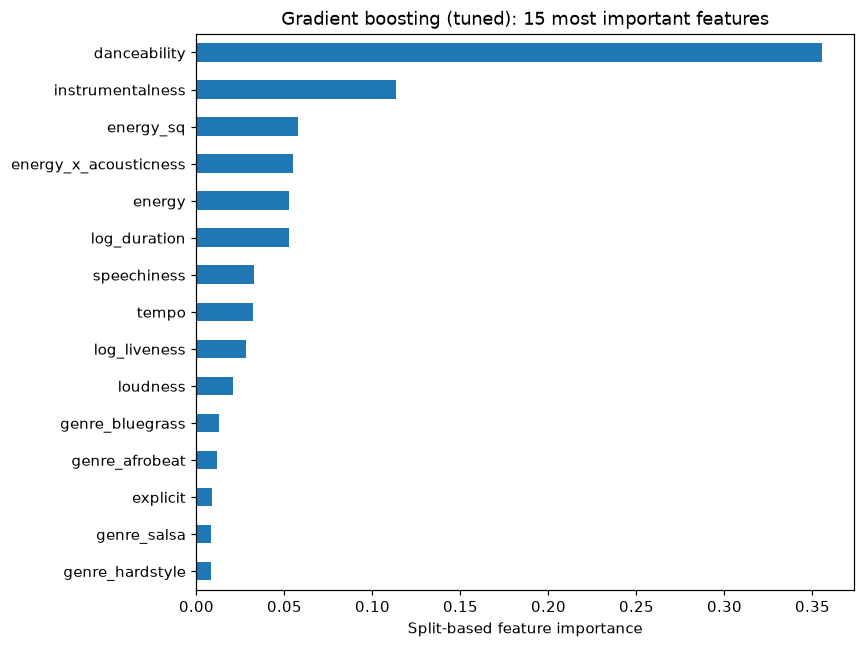

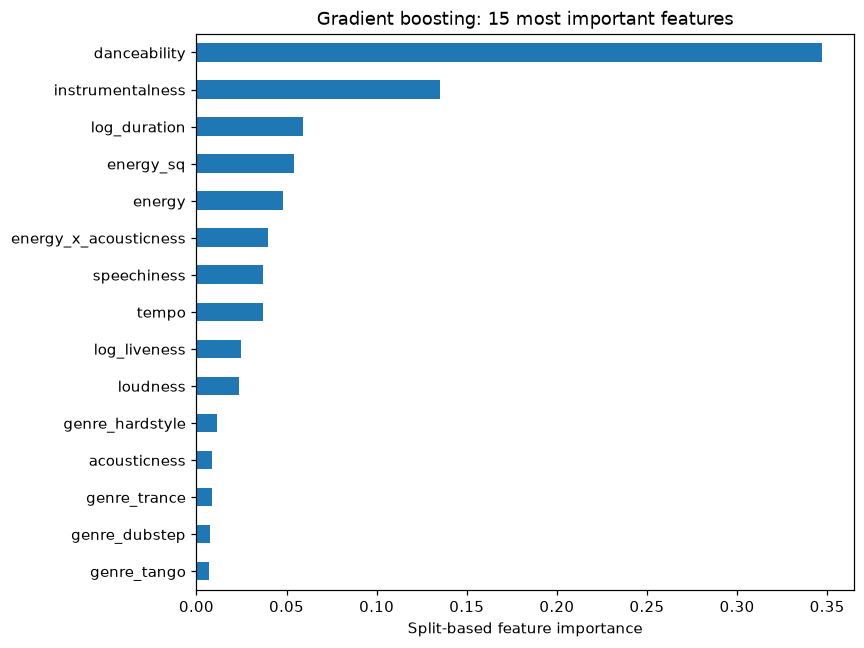

In [22]:
reg_cv = pd.DataFrame(reg_results).set_index("model")
best_reg_name = reg_cv.loc[list(tuned_reg), "RMSE"].idxmin()
best_reg = tuned_reg[best_reg_name]

for name, model in [(best_reg_name, best_reg), (best_clf_name, tuned_clf[best_clf_name])]:
    importance = pd.Series(model.feature_importances_, index=X.columns)
    importance.sort_values().tail(15).plot.barh(figsize=(8, 6))
    plt.xlabel("Split-based feature importance")
    plt.title(f"{name}: 15 most important features")
    plt.tight_layout()
    plt.show()

### 6.3 Regression errors

Use OOF predictions to plot predicted versus true valence and mean errors by valence range.

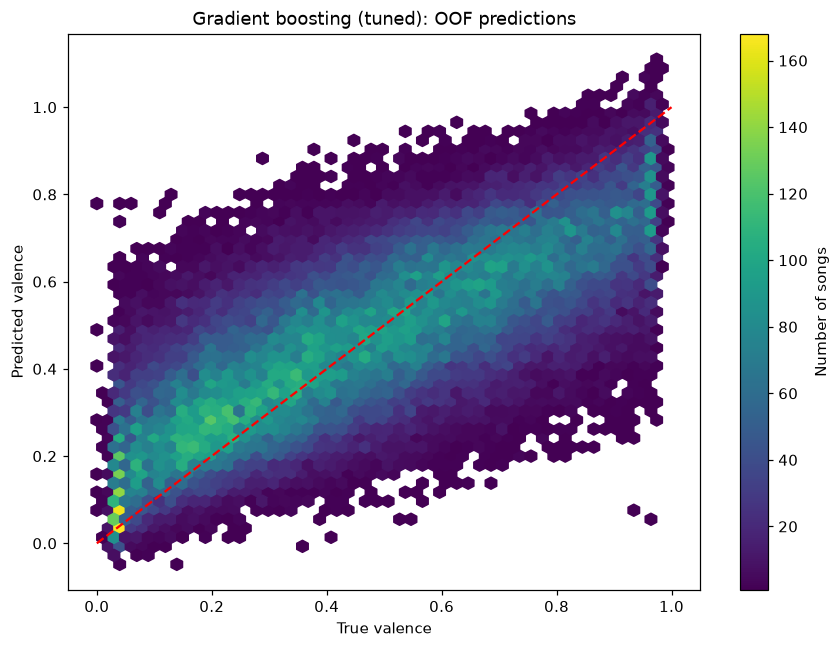

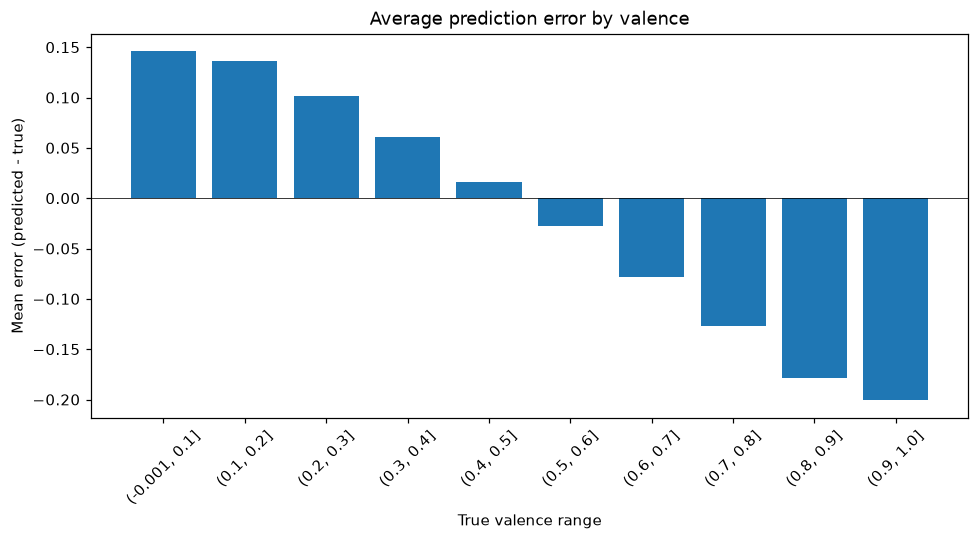

In [23]:
oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=N_JOBS)
resid = oof_pred - y

plt.figure(figsize=(8, 6))
plt.hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
plt.plot([0, 1], [0, 1], "--", color="red")
plt.xlabel("True valence")
plt.ylabel("Predicted valence")
plt.title(f"{best_reg_name}: OOF predictions")
plt.colorbar(label="Number of songs")
plt.tight_layout()
plt.show()

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
plt.figure(figsize=(9, 5))
plt.bar([str(b) for b in by_bin.index], by_bin.values)
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("True valence range")
plt.ylabel("Mean error (predicted - true)")
plt.title("Average prediction error by valence")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Compare prediction errors across low-, middle-, and high-energy songs with low valence, and songs with valence at least 0.3.

In [24]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4) ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "low valence, middle energy (0.4 to 0.7)": low & X["energy"].between(0.4, 0.7),
    "valence >= 0.3": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()), "MAE": resid[mask].abs().mean(), "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
display(error_by_group.round(3))

,songs,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.094,0.072
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.160,0.150
"low valence, middle energy (0.4 to 0.7)",5568.0,0.165,0.158
valence >= 0.3,43581.0,0.132,-0.057


## 7. Final test scores

Fit each selected model on the full training set and calculate its test scores. Use the classification thresholds selected from training OOF predictions.

In [25]:
test_df = pd.read_csv("test_features.csv")
X_test = test_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y_test = test_df["valence"]
y_test_sad = test_df["sad"]
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

final_reg = {"Baseline: predict mean": DummyRegressor(strategy="mean"), **tuned_reg}
test_reg = []
for name, model in final_reg.items():
    pred = clone(model).fit(X, y).predict(X_test)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 141) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,Decision tree (tuned),0.2002,0.1596,0.4034
2,Random forest (tuned),0.1773,0.1428,0.5321
3,Gradient boosting (tuned),0.1697,0.1339,0.5710


In [26]:
test_clf = []
base_clf = DummyClassifier(strategy="most_frequent").fit(X, y_sad)
base_pred = base_clf.predict(X_test)
test_clf.append({"model": "Baseline: always 'not sad'",
                 "test F1": f1_score(y_test_sad, base_pred), "test ROC-AUC": 0.5,
                 "test accuracy": (base_pred == y_test_sad).mean()})

for name, model in tuned_clf.items():
    proba = clone(model).fit(X, y_sad).predict_proba(X_test)[:, 1]
    for t in sorted({0.5, best_thresholds[name]}):
        pred = (proba >= t).astype(int)
        test_clf.append({"model": f"{name} (tuned, threshold {t:.2f})",
                         "test F1": f1_score(y_test_sad, pred),
                         "test ROC-AUC": roc_auc_score(y_test_sad, proba),
                         "test accuracy": (pred == y_test_sad).mean()})
pd.DataFrame(test_clf).round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,"Decision tree (tuned, threshold 0.33)",0.6303,0.8129,0.7427
2,"Decision tree (tuned, threshold 0.50)",0.5955,0.8129,0.7744
3,"Random forest (tuned, threshold 0.45)",0.6904,0.8648,0.7886
4,"Random forest (tuned, threshold 0.50)",0.6889,0.8648,0.8029
5,"Gradient boosting (tuned, threshold 0.36)",0.7046,0.8758,0.8035
6,"Gradient boosting (tuned, threshold 0.50)",0.6736,0.8758,0.8141


## 8. Save results

Combine CV and final test scores and save the regression and classification CSV files. Initial models have CV scores only.

In [27]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left",
                                            validate="one_to_one")
clf_table = pd.DataFrame(clf_results).merge(pd.DataFrame(test_clf), on="model", how="left",
                                            validate="one_to_one")
reg_table.to_csv("results_tree_regression.csv", index=False)
clf_table.to_csv("results_tree_classification.csv", index=False)
print("Saved results_tree_regression.csv and results_tree_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_tree_regression.csv and results_tree_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,Decision tree (initial),0.2574,0.0018,0.1982,0.0358,,NaN,NaN,NaN
2,Random forest (initial),0.1801,0.0010,0.1433,0.5278,,NaN,NaN,NaN
3,Gradient boosting (initial),0.1870,0.0015,0.1521,0.4910,,NaN,NaN,NaN
4,Decision tree (tuned),0.2005,0.0012,0.1597,0.4150,"{'max_depth': 12, 'min_samples_leaf': 50}",0.2002,0.1596,0.4034
5,Random forest (tuned),0.1780,0.0009,0.1440,0.5389,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.1773,0.1428,0.5321
6,Gradient boosting (tuned),0.1695,0.0010,0.1341,0.5820,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.1697,0.1339,0.5710


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,0.0000,0.5000,0.6903
1,Decision tree (initial),0.50,0.5732,0.6908,0.7355,,NaN,NaN,NaN
2,Random forest (initial),0.50,0.6500,0.8663,0.8090,,NaN,NaN,NaN
3,Gradient boosting (initial),0.50,0.6207,0.8565,0.7998,,NaN,NaN,NaN
4,"Decision tree (tuned, threshold 0.33)",0.33,0.6382,0.8193,0.7481,"{'class_weight': None, 'max_depth': 12, 'min_s...",0.6303,0.8129,0.7427
5,"Decision tree (tuned, threshold 0.50)",0.50,0.5972,0.8193,0.7763,"{'class_weight': None, 'max_depth': 12, 'min_s...",0.5955,0.8129,0.7744
6,"Random forest (tuned, threshold 0.45)",0.45,0.6980,0.8706,0.7957,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.6904,0.8648,0.7886
7,"Random forest (tuned, threshold 0.50)",0.50,0.6919,0.8706,0.8064,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.6889,0.8648,0.8029
8,"Gradient boosting (tuned, threshold 0.36)",0.36,0.7092,0.8808,0.8093,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.7046,0.8758,0.8035
9,"Gradient boosting (tuned, threshold 0.50)",0.50,0.6819,0.8808,0.8184,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.6736,0.8758,0.8141


### Summary

Print the CV-selected models' final test scores and the regression scores before and after tuning.

In [28]:
reg_selected = reg_table.set_index("model").loc[best_reg_name]
clf_selected_name = f"{best_clf_name} (tuned, threshold {best_t:.2f})"
clf_selected = clf_table.set_index("model").loc[clf_selected_name]
print(f"Selected regressor: {best_reg_name}")
print(f"Test RMSE {reg_selected['test RMSE']:.4f}, MAE {reg_selected['test MAE']:.4f}, "
      f"R2 {reg_selected['test R2']:.4f}")
print(f"Selected classifier: {best_clf_name}, threshold {best_t:.2f}")
print(f"Test F1 {clf_selected['test F1']:.4f}, ROC-AUC {clf_selected['test ROC-AUC']:.4f}")
for name in ["Decision tree", "Random forest", "Gradient boosting"]:
    initial = reg_cv.loc[f"{name} (initial)", "RMSE"]
    tuned = reg_cv.loc[f"{name} (tuned)", "RMSE"]
    print(f"{name}: CV RMSE {initial:.4f} -> {tuned:.4f} (initial -> tuned)")

Selected regressor: Gradient boosting (tuned)
Test RMSE 0.1697, MAE 0.1339, R2 0.5710
Selected classifier: Gradient boosting, threshold 0.36
Test F1 0.7046, ROC-AUC 0.8758
Decision tree: CV RMSE 0.2574 -> 0.2005 (initial -> tuned)
Random forest: CV RMSE 0.1801 -> 0.1780 (initial -> tuned)
Gradient boosting: CV RMSE 0.1870 -> 0.1695 (initial -> tuned)
